[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_energy/BA_L1_energy.ipynb)

# BA_L1_energy: Electricity Use of Bitcoin Mining

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Annualised electricity use of the Bitcoin network, 2015 to 22 November 2026, from the Cambridge Bitcoin Electricity Consumption Index (CBECI): best guess with its lower and upper bound, yearly means and the fall after the mining ban in China in 2021.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

The Cambridge Bitcoin Electricity Consumption Index estimates the power demand of the network from the hash rate and
the efficiency of mining machines, and annualises it in TWh. Which machines are running is not observed, so the index
gives a range: the lower bound assumes the most efficient machine for all miners, the upper bound the least efficient
machines that are still profitable at an electricity price of 0.05 USD per kWh.

**How to read the chart.** The band is wide: the upper bound is about three times the lower one. The best guess
follows the hash rate, with a sharp fall in mid-2021.

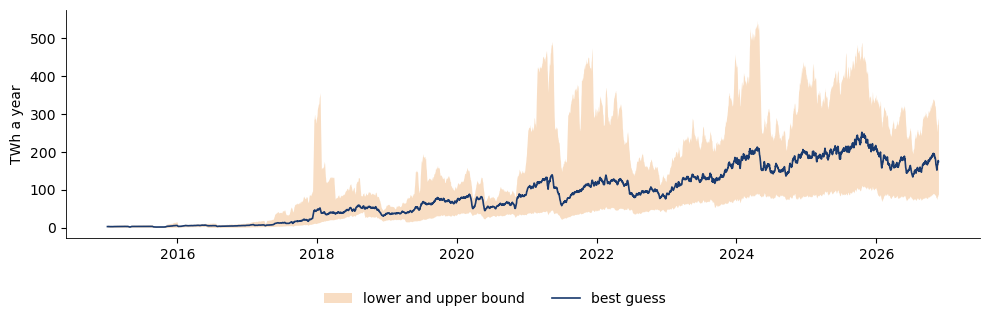

22 November 2026: best guess 174.6 TWh a year (power 19.9 GW), bounds 87.9 to 283.8 TWh
Highest best guess: 252.0 TWh (18 October 2025)
Yearly means of the best guess (TWh): {2017: 14.4, 2018: 45.4, 2019: 55.9, 2020: 68.6, 2021: 104.1, 2022: 105.4, 2023: 130.6, 2024: 174.0, 2025: 206.6, 2026: 169.5}
2025: Bitcoin 206.6 TWh = 3.8 x Romania (54.4 TWh), 1.19 x Poland (174.3 TWh), 0.65% of world demand (31,772 TWh)
May 2021: 122.8 TWh; July 2021, after the mining ban in China: 67.2 TWh


In [5]:
# Cambridge Bitcoin Electricity Consumption Index: annualised electricity use of Bitcoin mining
cb = pd.read_csv(data_file('indices', 'cbeci_bitcoin_electricity.csv'), parse_dates=['date']).set_index('date').loc['2015':]

fig, ax = plt.subplots(figsize=(10, 3.2))
ax.fill_between(cb.index, cb['twh_min'], cb['twh_max'], color=BTC, alpha=0.3, lw=0, label='lower and upper bound')
ax.plot(cb.index, cb['twh_guess'], color=BLUE, lw=1.2, label='best guess')
ax.set_ylabel('TWh a year')
legend_below(fig, ncol=2, bottom=0.12)
save_fig(fig, 'ba_l1_energy')

last = cb.iloc[-1]
print(f'{cb.index[-1]:%d %B %Y}: best guess {last["twh_guess"]:.1f} TWh a year (power {last["power_guess_gw"]:.1f} GW), '
      f'bounds {last["twh_min"]:.1f} to {last["twh_max"]:.1f} TWh')
print(f'Highest best guess: {cb["twh_guess"].max():.1f} TWh ({cb["twh_guess"].idxmax():%d %B %Y})')
print('Yearly means of the best guess (TWh):', cb['twh_guess'].groupby(cb.index.year).mean().round(1).loc[2017:].to_dict())
dm = pd.read_csv(data_file('indices', 'electricity_demand_ember.csv'))
dm = dm[dm['year'] == 2025].set_index('entity')['demand_twh']                  # national electricity demand, Ember
b25 = cb.loc['2025', 'twh_guess'].mean()
print(f'2025: Bitcoin {b25:.1f} TWh = {b25 / dm["Romania"]:.1f} x Romania ({dm["Romania"]:.1f} TWh), '
      f'{b25 / dm["Poland"]:.2f} x Poland ({dm["Poland"]:.1f} TWh), {100 * b25 / dm["World"]:.2f}% of world demand ({dm["World"]:,.0f} TWh)')
print(f'May 2021: {cb.loc["2021-05", "twh_guess"].mean():.1f} TWh; July 2021, after the mining ban in China: {cb.loc["2021-07", "twh_guess"].mean():.1f} TWh')